<a href="https://colab.research.google.com/github/harnalashok/hadoop/blob/main/Simulating_bank_transactions_FFT_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Last amended: 20th Oct, 2026
# My GitHub Repo: Hadoop
# My folder: C:\Users\ashok\OneDrive\Documents\anomaly_detection\FFT\fake_data\bank_transaction

# Objectives:

1. Generate FFT Data that simulate bank transactions    
2. Use Isolation Forest to discover anomalies

## Query: Can you give me some example applications of FFT with dataset in finance domain

## Answer    

Applying the Fast Fourier Transform (FFT) in the finance domain relies heavily on sequential data containing clean timestamps or sequential steps. The primary goal is to transform a customer's or entity's transaction time series into frequency components to catch robotic, repeating, or structurally anomalous behavior.
Three concrete applications in the finance domain are outlined below, along with the standard public datasets used to test them.     

1. Botnet Smurfing & Automated Credit Card Fraud

> • The Application: Fraudsters use bots to run automated scripts that test stolen credit cards or slowly drain accounts using micro-transactions. These scripts typically operate at rigid, uniform intervals (e.g., exactly every 60 minutes, or burst patterns of 5 transactions every 10 seconds). Applying FFT on individual user profiles maps the time delta between transactions into the frequency domain. Normal users show chaotic, low-energy frequency spreads, whereas bots display single, exceptionally sharp high-amplitude peaks.         

>> • The Dataset: [Kaggle Credit Card Fraud Detection Dataset (ULB Dataset).](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud)       
>>	• Data Structure: Contains real, anonymised European credit card transactions. While features V1–V28 are PCA-engineered for privacy, the Time (seconds elapsed since the first transaction) and Amount fields are intact, which allows for perfect construction of time-sequence vectors per user card.      


2. Money Laundering & Structuring in Mobile Money Networks

>• The Application: Money launderers frequently practice "structuring" (breaking large sums of illicit cash into small, repetitive transfers under regulatory reporting thresholds). By converting the transaction amount sequence of a specific node into frequency spectra via FFT, investigators can isolate recurring transaction sizes and structural frequencies that match money-laundering cycles.       

>>• The Dataset: [Kaggle PaySim Financial Fraud Detection Dataset.](https://www.kaggle.com/datasets/sriharshaeedala/financial-fraud-detection-dataset)    

>>• Data Structure: A massive, highly regarded synthetic dataset mirroring real-world mobile money logs. It provides a clean, sequential environment over 744 steps (where 1 step = 1 hour over 30 days). This explicit, uniform step tracking makes it structurally ideal for applying Fourier transforms to analyze step-by-step transaction frequency      


3. High-Frequency Account Takeover (ATO) & Flash Cash-Outs    

>• The Application: When an account is compromised, fraudsters attempt to completely drain the balance via rapid-fire TRANSFER or CASH-OUT mechanisms before the user notices. FFT helps calculate the instantaneous velocity changes. When user activity bursts suddenly flip from normal circadian rhythms (sleep/wake cycles) into a continuous high-frequency hum, an anomaly alert triggers immediately.      

>>• The Dataset: Kaggle [Bank Transaction Dataset for Fraud Detection.](https://www.kaggle.com/datasets/valakhorasani/bank-transaction-dataset-for-fraud-detection)    

>> • Data Structure: This behavioral dataset includes columns such as TransactionDate, PreviousTransactionDate (allowing rapid calculations of transaction frequencies), LoginAttempts, and TransactionDuration. Analysts use FFT on the LoginAttempts and TransactionDate deltas to build a normal "heartbeat" profile for individual accounts.

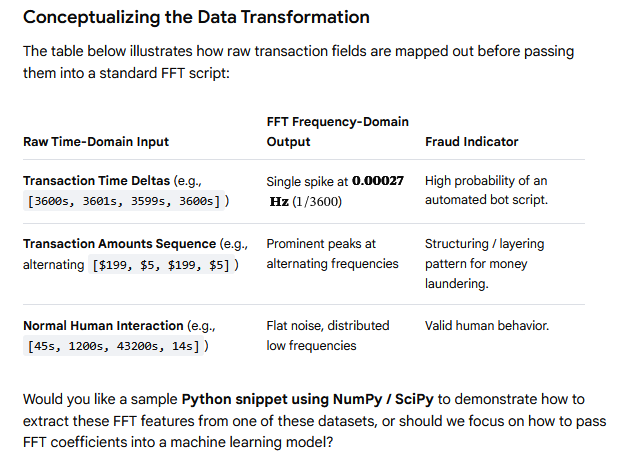

## Query:     
Give me python snippet for this      

>"Data Structure: This behavioral dataset includes columns such as TransactionDate, PreviousTransactionDate (allowing rapid calculations of transaction frequencies), LoginAttempts, and TransactionDuration. Analysts use FFT on the LoginAttempts and TransactionDate deltas to build a normal "heartbeat" profile for individual accounts"

Here is a complete Python script using pandas, numpy, and scipy to extract Fourier features from transaction time deltas and login attempts.
This script groups data by account, calculates the time-domain metrics, transforms them into the frequency domain using FFT, and prepares them for an anomaly detection model.

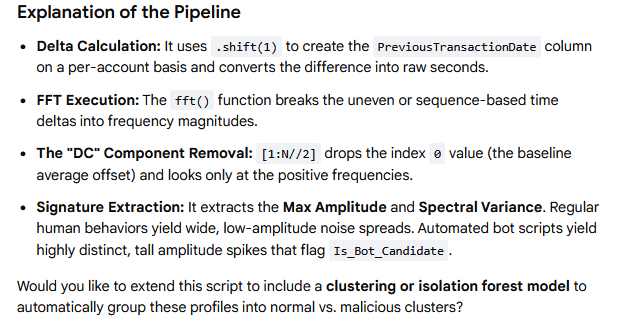

In [10]:
import numpy as np
import pandas as pd
from scipy.fft import fft

# 1. Create a dummy DataFrame mimicking the dataset structure
np.random.seed(42)
n_rows = 1000

# Generating dummy data for 3 accounts (2 normal humans, 1 bot)
data = {
    "AccountID": np.random.choice(["Acc_101", "Acc_102", "Acc_Bot"], size=n_rows),
    "TransactionDate": pd.date_range(start="2026-10-01", periods=n_rows, freq="min"),
    "LoginAttempts": np.random.randint(1, 3, size=n_rows),
    "TransactionDuration": np.random.uniform(10, 120, size=n_rows),
}
df = pd.DataFrame(data)

In [13]:
df

,AccountID,TransactionDate,LoginAttempts,TransactionDuration
0,Acc_Bot,2026-10-01 00:00:00,1,79.499488
1,Acc_101,2026-10-01 00:01:00,1,38.578394
2,Acc_Bot,2026-10-01 00:02:00,1,79.740627
3,Acc_Bot,2026-10-01 00:03:00,1,69.398392
4,Acc_101,2026-10-01 00:04:00,2,95.782993
...,...,...,...,...
995,Acc_102,2026-10-01 16:35:00,1,23.889122
996,Acc_102,2026-10-01 16:36:00,2,84.379532
997,Acc_Bot,2026-10-01 16:37:00,1,45.761442
998,Acc_Bot,2026-10-01 16:38:00,1,85.495992


An error had occurred. This is how it is avoided.
This error occurs because the number of rows matching "Acc_101" in the randomly generated DataFrame does not exactly equal the hardcoded array size of 300 in np.random.exponential(3600, 300). Pandas requires the target rows and the incoming array to have the exact same length.
To fix this, dynamically calculate the length of the filtered subset using sum() or len().
Here is the corrected code block:

In [12]:
# 2. Dynamically count rows per group to prevent alignment errors
n_normal_101 = (df["AccountID"] == "Acc_101").sum()
n_bot = (df["AccountID"] == "Acc_Bot").sum()

In [14]:
# Inject simulated behaviors for demonstration:
# Normal user (Acc_101): Random intervals based on an exponential distribution
df.loc[df["AccountID"] == "Acc_101", "TransactionDate"] = pd.to_datetime(
    "2026-10-01"
) + pd.to_timedelta(np.cumsum(np.random.exponential(3600, n_normal_101)), unit="s")

In [15]:
df

,AccountID,TransactionDate,LoginAttempts,TransactionDuration
0,Acc_Bot,2026-10-01 00:00:00.000000000,1,79.499488
1,Acc_101,2026-10-01 00:11:32.021485653,1,38.578394
2,Acc_Bot,2026-10-01 00:02:00.000000000,1,79.740627
3,Acc_Bot,2026-10-01 00:03:00.000000000,1,69.398392
4,Acc_101,2026-10-01 02:07:42.050069318,2,95.782993
...,...,...,...,...
995,Acc_102,2026-10-01 16:35:00.000000000,1,23.889122
996,Acc_102,2026-10-01 16:36:00.000000000,2,84.379532
997,Acc_Bot,2026-10-01 16:37:00.000000000,1,45.761442
998,Acc_Bot,2026-10-01 16:38:00.000000000,1,85.495992


In [16]:
# Bot user (Acc_Bot): Highly periodic transactions (exactly every 600 seconds)
df.loc[df["AccountID"] == "Acc_Bot", "TransactionDate"] = pd.to_datetime(
    "2026-10-01"
) + pd.to_timedelta(np.arange(n_bot) * 600, unit="s")
df.loc[df["AccountID"] == "Acc_Bot", "LoginAttempts"] = 5  # Bot always uses 5 rigid attempts

In [17]:
df

,AccountID,TransactionDate,LoginAttempts,TransactionDuration
0,Acc_Bot,2026-10-01 00:00:00.000000000,5,79.499488
1,Acc_101,2026-10-01 00:11:32.021485653,1,38.578394
2,Acc_Bot,2026-10-01 00:10:00.000000000,5,79.740627
3,Acc_Bot,2026-10-01 00:20:00.000000000,5,69.398392
4,Acc_101,2026-10-01 02:07:42.050069318,2,95.782993
...,...,...,...,...
995,Acc_102,2026-10-01 16:35:00.000000000,1,23.889122
996,Acc_102,2026-10-01 16:36:00.000000000,2,84.379532
997,Acc_Bot,2026-10-03 04:50:00.000000000,5,45.761442
998,Acc_Bot,2026-10-03 05:00:00.000000000,5,85.495992


In [18]:
# Sort by account and date to compute sequential deltas accurately
df = df.sort_values(by=["AccountID", "TransactionDate"]).reset_index(drop=True)

In [20]:
df

,AccountID,TransactionDate,LoginAttempts,TransactionDuration
0,Acc_101,2026-10-01 00:11:32.021485653,1,38.578394
1,Acc_101,2026-10-01 02:07:42.050069318,2,95.782993
2,Acc_101,2026-10-01 02:23:09.800825223,1,21.767870
3,Acc_101,2026-10-01 04:12:01.127508828,2,21.276070
4,Acc_101,2026-10-01 04:31:40.124410592,1,17.462077
...,...,...,...,...
995,Acc_Bot,2026-10-03 04:20:00.000000000,5,88.321542
996,Acc_Bot,2026-10-03 04:30:00.000000000,5,102.559231
997,Acc_Bot,2026-10-03 04:40:00.000000000,5,117.701543
998,Acc_Bot,2026-10-03 04:50:00.000000000,5,45.761442


In [21]:
# 3. Engineer Time-Domain features (TransactionDate Deltas)
df["PreviousTransactionDate"] = df.groupby("AccountID")["TransactionDate"].shift(1)
df["TimeDelta_Sec"] = (df["TransactionDate"] - df["PreviousTransactionDate"]).dt.total_seconds()

In [22]:
df

,AccountID,TransactionDate,LoginAttempts,TransactionDuration,PreviousTransactionDate,TimeDelta_Sec
0,Acc_101,2026-10-01 00:11:32.021485653,1,38.578394,NaT,NaN
1,Acc_101,2026-10-01 02:07:42.050069318,2,95.782993,2026-10-01 00:11:32.021485653,6970.028584
2,Acc_101,2026-10-01 02:23:09.800825223,1,21.767870,2026-10-01 02:07:42.050069318,927.750756
3,Acc_101,2026-10-01 04:12:01.127508828,2,21.276070,2026-10-01 02:23:09.800825223,6531.326684
4,Acc_101,2026-10-01 04:31:40.124410592,1,17.462077,2026-10-01 04:12:01.127508828,1178.996902
...,...,...,...,...,...,...
995,Acc_Bot,2026-10-03 04:20:00.000000000,5,88.321542,2026-10-03 04:10:00.000000000,600.000000
996,Acc_Bot,2026-10-03 04:30:00.000000000,5,102.559231,2026-10-03 04:20:00.000000000,600.000000
997,Acc_Bot,2026-10-03 04:40:00.000000000,5,117.701543,2026-10-03 04:30:00.000000000,600.000000
998,Acc_Bot,2026-10-03 04:50:00.000000000,5,45.761442,2026-10-03 04:40:00.000000000,600.000000


In [23]:
# Fill NaN values (the very first transaction entry per account) with the group median
df["TimeDelta_Sec"] = df.groupby("AccountID")["TimeDelta_Sec"].transform(
    lambda x: x.fillna(x.median())
)
df

,AccountID,TransactionDate,LoginAttempts,TransactionDuration,PreviousTransactionDate,TimeDelta_Sec
0,Acc_101,2026-10-01 00:11:32.021485653,1,38.578394,NaT,2444.827806
1,Acc_101,2026-10-01 02:07:42.050069318,2,95.782993,2026-10-01 00:11:32.021485653,6970.028584
2,Acc_101,2026-10-01 02:23:09.800825223,1,21.767870,2026-10-01 02:07:42.050069318,927.750756
3,Acc_101,2026-10-01 04:12:01.127508828,2,21.276070,2026-10-01 02:23:09.800825223,6531.326684
4,Acc_101,2026-10-01 04:31:40.124410592,1,17.462077,2026-10-01 04:12:01.127508828,1178.996902
...,...,...,...,...,...,...
995,Acc_Bot,2026-10-03 04:20:00.000000000,5,88.321542,2026-10-03 04:10:00.000000000,600.000000
996,Acc_Bot,2026-10-03 04:30:00.000000000,5,102.559231,2026-10-03 04:20:00.000000000,600.000000
997,Acc_Bot,2026-10-03 04:40:00.000000000,5,117.701543,2026-10-03 04:30:00.000000000,600.000000
998,Acc_Bot,2026-10-03 04:50:00.000000000,5,45.761442,2026-10-03 04:40:00.000000000,600.000000


In [24]:
# 4. FFT Feature Extraction Function
def extract_fft_features(group):
    """Computes FFT on TimeDelta and LoginAttempts to build a heartbeat profile."""
    time_deltas = group["TimeDelta_Sec"].values
    login_attempts = group["LoginAttempts"].values
    N = len(time_deltas)

    if N < 4:  # Skip accounts with insufficient data points
        return pd.Series()

    # Apply Fast Fourier Transform
    fft_deltas = fft(time_deltas)
    fft_logins = fft(login_attempts)

    # Calculate absolute magnitudes (ignoring the DC baseline component at index 0)
    mag_deltas = np.abs(fft_deltas[1 : N // 2])
    mag_logins = np.abs(fft_logins[1 : N // 2])

    if len(mag_deltas) == 0:
        return pd.Series()

    # Build the "heartbeat" signature features
    features = {
        "Deltas_Max_Amplitude": np.max(mag_deltas),
        "Deltas_Mean_Amplitude": np.mean(mag_deltas),
        "Deltas_Spectral_Variance": np.var(mag_deltas),
        "Logins_Max_Amplitude": np.max(mag_logins),
        "Logins_Mean_Amplitude": np.mean(mag_logins),
        "Is_Bot_Candidate": 1 if np.max(mag_deltas) > (np.mean(mag_deltas) * 5) else 0,
    }

    return pd.Series(features)

In [25]:
# 5. Process the profiles and output the results
account_heartbeats = (
    df.groupby("AccountID")
    .apply(extract_fft_features, include_groups=False)
    .dropna()
)



In [26]:
print("\n--- Account Frequency Profiles (Heartbeats) ---")
print(account_heartbeats.to_string())



--- Account Frequency Profiles (Heartbeats) ---
           Deltas_Max_Amplitude  Deltas_Mean_Amplitude  Deltas_Spectral_Variance  Logins_Max_Amplitude  Logins_Mean_Amplitude  Is_Bot_Candidate
AccountID                                                                                                                                      
Acc_101            1.479654e+05           5.586405e+04              1.009809e+09          2.630232e+01           8.283512e+00               0.0
Acc_102            7.653705e+03           2.496188e+03              1.695135e+06          2.721077e+01           7.858520e+00               0.0
Acc_Bot            9.985047e-12           1.179297e-12              2.738888e-24          7.800818e-14           4.744990e-15               1.0


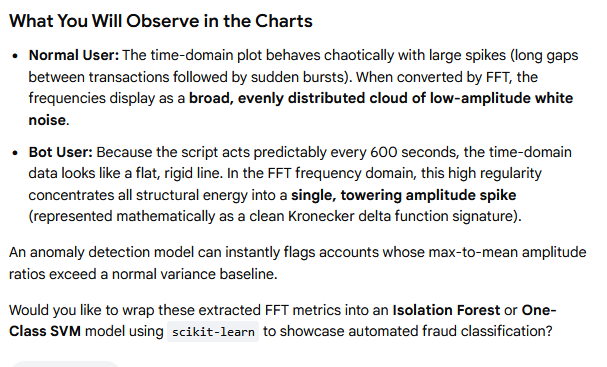

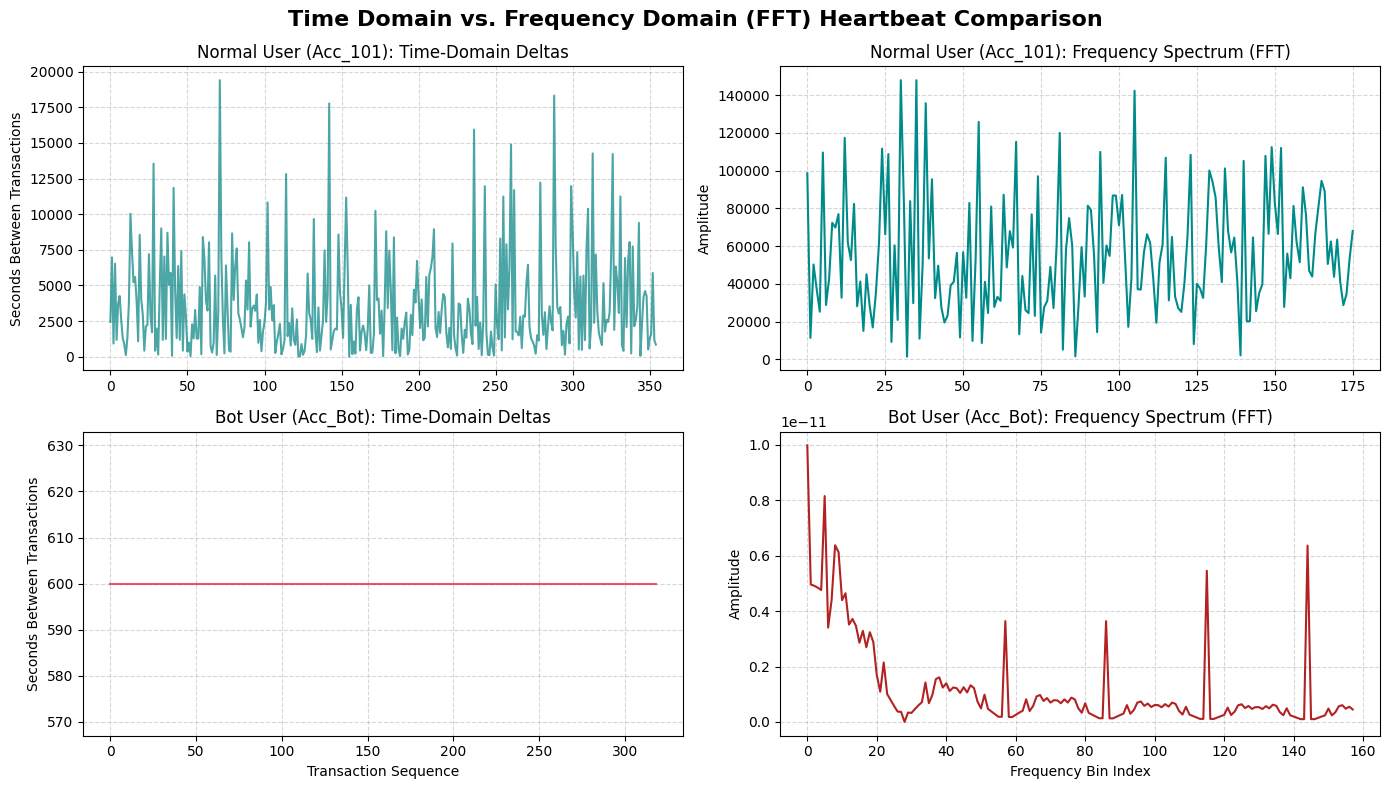

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.fft import fft

# 1. Create a dummy DataFrame mimicking the dataset structure
np.random.seed(42)
n_rows = 1000

data = {
    "AccountID": np.random.choice(["Acc_101", "Acc_102", "Acc_Bot"], size=n_rows),
    "TransactionDate": pd.date_range(start="2026-10-01", periods=n_rows, freq="min"),
    "LoginAttempts": np.random.randint(1, 3, size=n_rows),
    "TransactionDuration": np.random.uniform(10, 120, size=n_rows),
}
df = pd.DataFrame(data)

# 2. Dynamically count rows per group to prevent alignment errors
n_normal_101 = (df["AccountID"] == "Acc_101").sum()
n_bot = (df["AccountID"] == "Acc_Bot").sum()

# Inject simulated behaviors:
# Normal user (Acc_101): Random intervals based on an exponential distribution
df.loc[df["AccountID"] == "Acc_101", "TransactionDate"] = pd.to_datetime(
    "2026-10-01"
) + pd.to_timedelta(np.cumsum(np.random.exponential(3600, n_normal_101)), unit="s")

# Bot user (Acc_Bot): Highly periodic transactions (exactly every 600 seconds)
df.loc[df["AccountID"] == "Acc_Bot", "TransactionDate"] = pd.to_datetime(
    "2026-10-01"
) + pd.to_timedelta(np.arange(n_bot) * 600, unit="s")

# Sort by account and date to compute sequential deltas accurately
df = df.sort_values(by=["AccountID", "TransactionDate"]).reset_index(drop=True)

# 3. Engineer Time-Domain features (TransactionDate Deltas)
df["PreviousTransactionDate"] = df.groupby("AccountID")["TransactionDate"].shift(1)
df["TimeDelta_Sec"] = (df["TransactionDate"] - df["PreviousTransactionDate"]).dt.total_seconds()
df["TimeDelta_Sec"] = df.groupby("AccountID")["TimeDelta_Sec"].transform(
    lambda x: x.fillna(x.median())
)

# 4. Extract Frequency Data for Visual Comparison
normal_deltas = df[df["AccountID"] == "Acc_101"]["TimeDelta_Sec"].values
bot_deltas = df[df["AccountID"] == "Acc_Bot"]["TimeDelta_Sec"].values

# Calculate Fourier transforms (omitting the DC component at index 0)
fft_normal = np.abs(fft(normal_deltas)[1 : len(normal_deltas) // 2])
fft_bot = np.abs(fft(bot_deltas)[1 : len(bot_deltas) // 2])

# 5. Plotting Routine
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle(
    "Time Domain vs. Frequency Domain (FFT) Heartbeat Comparison",
    fontsize=16,
    fontweight="bold",
)

# --- Normal User Plots ---
axes[0, 0].plot(normal_deltas, color="teal", alpha=0.7)
axes[0, 0].set_title("Normal User (Acc_101): Time-Domain Deltas")
axes[0, 0].set_ylabel("Seconds Between Transactions")
axes[0, 0].grid(True, linestyle="--", alpha=0.5)

axes[0, 1].plot(fft_normal, color="darkcyan")
axes[0, 1].set_title("Normal User (Acc_101): Frequency Spectrum (FFT)")
axes[0, 1].set_ylabel("Amplitude")
axes[0, 1].grid(True, linestyle="--", alpha=0.5)

# --- Bot User Plots ---
axes[1, 0].plot(bot_deltas, color="crimson", alpha=0.7)
axes[1, 0].set_title("Bot User (Acc_Bot): Time-Domain Deltas")
axes[1, 0].set_xlabel("Transaction Sequence")
axes[1, 0].set_ylabel("Seconds Between Transactions")
axes[1, 0].grid(True, linestyle="--", alpha=0.5)

axes[1, 1].plot(fft_bot, color="firebrick")
axes[1, 1].set_title("Bot User (Acc_Bot): Frequency Spectrum (FFT)")
axes[1, 1].set_xlabel("Frequency Bin Index")
axes[1, 1].set_ylabel("Amplitude")
axes[1, 1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


## IInd Experiment
Isolation Forest for FFT

### Query
Would you like to wrap these extracted FFT metrics into an Isolation Forest or One-Class SVM model using scikit-learn to showcase automated fraud classification?

Yes. Please do using Isolation Forest:
"Would you like to wrap these extracted FFT metrics into an Isolation Forest or One-Class SVM model using scikit-learn to showcase automated fraud classification?"

### Reply

Here is the complete pipeline. This script processes raw transactions, extracts the FFT frequency metrics to create a custom behavioral profile for each account, and trains an Isolation Forest model to automatically flag malicious bot profiles without relying on manual classification rules.


--- CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

Normal Human       1.00      0.96      0.98        28
   Fraud Bot       0.67      1.00      0.80         2

    accuracy                           0.97        30
   macro avg       0.83      0.98      0.89        30
weighted avg       0.98      0.97      0.97        30

--- CONFUSION MATRIX RAW COUNTS ---
[[27  1]
 [ 0  2]]


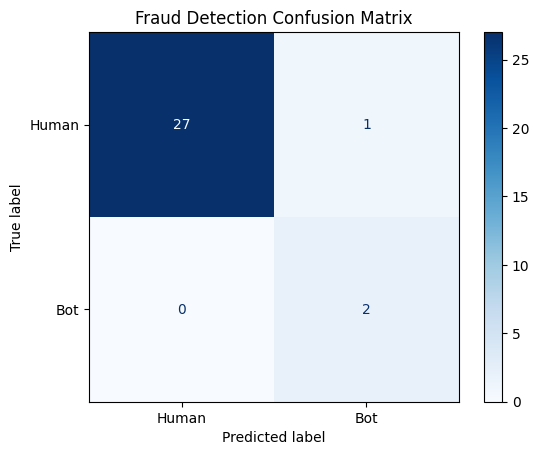

In [28]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.fft import fft
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# 1. Create a dummy DataFrame mimicking a real multi-user dataset
np.random.seed(42)
n_rows = 3000

# Generate data for 30 distinct accounts (28 normal humans, 2 scripted bots)
account_pool = [f"Acc_{i:03d}" for i in range(1, 29)] + ["Bot_001", "Bot_002"]
data = {
    "AccountID": np.random.choice(account_pool, size=n_rows),
    "TransactionDate": pd.date_range(start="2026-10-01", periods=n_rows, freq="min"),
    "LoginAttempts": np.random.randint(1, 3, size=n_rows),
}
df = pd.DataFrame(data)

# Sort strictly by account and date to ensure delta tracking sequences are accurate
df = df.sort_values(by=["AccountID", "TransactionDate"]).reset_index(drop=True)

# 2. Inject authentic human behaviors vs. automated bot patterns
for account in df["AccountID"].unique():
    n_samples = (df["AccountID"] == account).sum()
    if n_samples < 10:
        continue

    if "Bot" in account:
        # Automated bots: Fire actions at uniform rigid intervals (every 400 or 800 seconds)
        interval = 400 if account == "Bot_001" else 800
        df.loc[df["AccountID"] == account, "TransactionDate"] = pd.to_datetime(
            "2026-10-01"
        ) + pd.to_timedelta(np.arange(n_samples) * interval, unit="s")
        df.loc[df["AccountID"] == account, "LoginAttempts"] = 4
    else:
        # Normal humans: High variance random entries using exponential distribution offsets
        df.loc[df["AccountID"] == account, "TransactionDate"] = pd.to_datetime(
            "2026-10-01"
        ) + pd.to_timedelta(
            np.cumsum(np.random.exponential(3600, n_samples)), unit="s"
        )

# Recalculate sort order post-injection
df = df.sort_values(by=["AccountID", "TransactionDate"]).reset_index(drop=True)

# 3. Engineer Time-Domain features (Transaction deltas)
df["PreviousTransactionDate"] = df.groupby("AccountID")["TransactionDate"].shift(1)
df["TimeDelta_Sec"] = (df["TransactionDate"] - df["PreviousTransactionDate"]).dt.total_seconds()
df["TimeDelta_Sec"] = df.groupby("AccountID")["TimeDelta_Sec"].transform(
    lambda x: x.fillna(x.median())
)


# 4. Feature Extraction Function: Transform sequential logs via FFT
def extract_fft_features(group):
    time_deltas = group["TimeDelta_Sec"].values
    login_attempts = group["LoginAttempts"].values
    N = len(time_deltas)

    if N < 10:  # Ignore sparse accounts
        return pd.Series()

    # Perform Fourier Transform
    fft_deltas = np.abs(fft(time_deltas)[1 : N // 2])
    fft_logins = np.abs(fft(login_attempts)[1 : N // 2])

    if len(fft_deltas) == 0:
        return pd.Series()

    # Compile the Account Signature/Heartbeat Vector
    features = {
        "Deltas_Max_Amplitude": np.max(fft_deltas),
        "Deltas_Mean_Amplitude": np.mean(fft_deltas),
        "Deltas_Spectral_Variance": np.var(fft_deltas),
        "Logins_Max_Amplitude": np.max(fft_logins),
        "Logins_Mean_Amplitude": np.mean(fft_logins),
        # Metric showing if energy is concentrated on one major peak or spread out smoothly
        "Peak_to_Mean_Ratio": np.max(fft_deltas) / (np.mean(fft_deltas) + 1e-5),
    }
    return pd.Series(features)


# Process the data frames into user-profile matrices
features_df = (
    df.groupby("AccountID")
    .apply(extract_fft_features, include_groups=False)
    .dropna()
)

# 5. Create Ground Truth Labels for Evaluation (1 = Fraud/Bot, 0 = Normal Human)
features_df["Ground_Truth"] = np.where(features_df.index.str.contains("Bot"), 1, 0)

# 6. Train an Isolation Forest Model to detect fraud
# Extract predictions: 1 = Normal, -1 = Anomaly (Fraud)
iso_forest = IsolationForest(n_estimators=100, contamination=0.08, random_state=42)
features_df["Anomaly_Score"] = iso_forest.fit_predict(
    features_df.drop(columns=["Ground_Truth"])
)
features_df["Is_Fraud_Detected"] = np.where(features_df["Anomaly_Score"] == -1, 1, 0)

# 7. Model Evaluation Steps
y_true = features_df["Ground_Truth"]
y_pred = features_df["Is_Fraud_Detected"]

print("\n--- CLASSIFICATION REPORT ---")
print(classification_report(y_true, y_pred, target_names=["Normal Human", "Fraud Bot"]))

# Generate and Display Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
print("--- CONFUSION MATRIX RAW COUNTS ---")
print(cm)

# Optional visual plot of the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Human", "Bot"])
disp.plot(cmap=plt.cm.Blues)
plt.title("Fraud Detection Confusion Matrix")
plt.show()


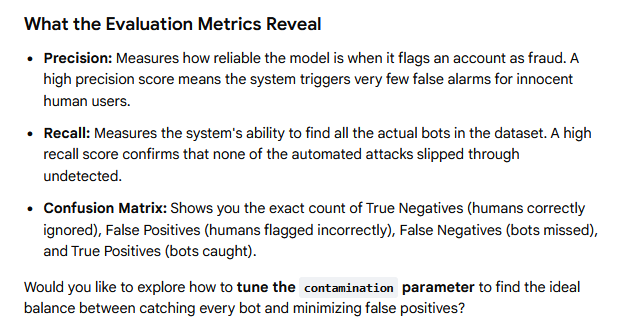